age vs gpa corr: -0.0016
study vs exam score corr: 0.3632
parent_education
Bachelor       2.780107
Associate      2.780377
High School    2.780420
Master         2.783405
Doctorate      2.783560
Name: previous_gpa, dtype: float64


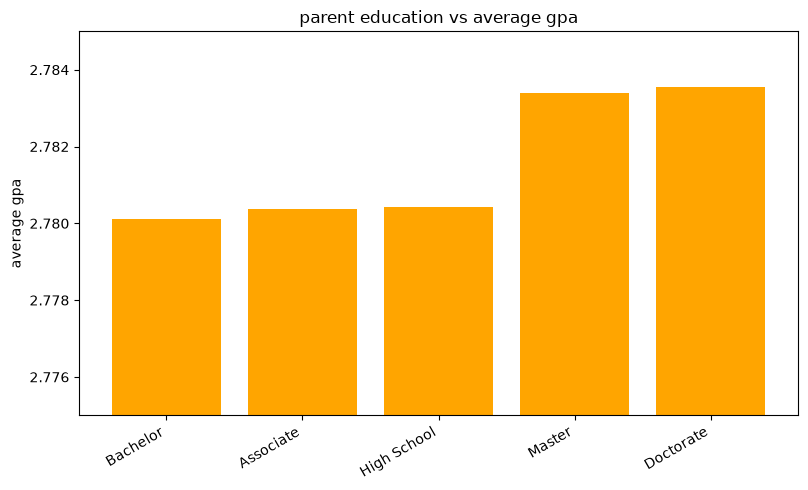

correlation age vs previous_gpa: -0.0016
interpretation: WEAK/NO RELATIONS _age does not affect gpa mush

correlation study_hour vs exam_score: 0.3632
interpretation: MODERATE POSITIVE _ higher study hours gives higher exam score

aveerage gpa by parent_education:
parent_education
Bachelor       2.780107
Associate      2.780377
High School    2.780420
Master         2.783405
Doctorate      2.783560
difference between highest and lowest gpa: 0.0035
interpretation: WEAK/NO EFFECT _ parent education does not affect gpa much
lenght: 526


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn

fd = pd.read_csv("cleaned_data_100k.csv")

corr_age = fd['age'].corr(fd['previous_gpa'])
corr_study = fd['study_hours_per_day'].corr(fd['exam_score'])

avg_gpa_by_parent = fd.groupby('parent_education')['previous_gpa'].mean().sort_values()
#avg_score_by_parent = fd.groupby('parent_education')['exam_score'].mean().sort_values()

print(f"age vs gpa corr: {corr_age:.4f}")
print(f"study vs exam score corr: {corr_study:.4f}")
print(avg_gpa_by_parent)
with open("result2.txt", "w") as file:
    #age
    file.write(f"correlation age vs previous_gpa: {corr_age:.4f}\n")
    if corr_age >= 0.7:
        file.write("interpretation: STRONG POSITIVE _ as age increasees, gpa strongly increases\n\n")
    elif corr_age >= 0.3:
        file.write("interpretation: MODERATE POSITIVE _ higher age gives higher gpa\n\n")
    elif corr_age > -0.3:
        file.write("interpretation: WEAK/NO RELATIONS _age does not affect gpa mush\n\n")
    elif corr_age > -0.7:
        file.write("interpretation: MODERATE NAGATIVE _ as age increases, gpa decreases\n\n")
    else:
        file.write("interpretation: STRONG NEGATIVE _ higher age = lower gpa\n\n")

        #study hours
    file.write(f"correlation study_hour vs exam_score: {corr_study:.4f}\n")
    if corr_study >= 0.7:
        file.write("interpretation: STRONG POSITIVE _ study hour strongly increases exam score\n\n")
    elif corr_study >= 0.3:
        file.write("interpretation: MODERATE POSITIVE _ higher study hours gives higher exam score\n\n")
    elif corr_study > -0.3:
        file.write("interpretation: WEAK/NO RELATIONS _study hours  does not affect exam score mush\n\n")
    elif corr_study > -0.7:
        file.write("interpretation: MODERATE NAGATIVE _ as study hour increases, exam score decreases\n\n")
    else:
        file.write("interpretation: STRONG NEGATIVE _ higher age = lower gpa\n\n")

        #parent education

    file.write(f"aveerage gpa by parent_education:\n{avg_gpa_by_parent.to_string()}\n")

    diff = avg_gpa_by_parent.max() - avg_gpa_by_parent.min()
    file.write(f"difference between highest and lowest gpa: {diff:.4f}\n")

    if diff >=0.5:
        file.write("interpretation: STRONG EFFECT _ parent education strongly affect gpa.\n")
    elif diff >= 0.2:
        file.write("interpretation: MODERATE EFFECT _ parent education has moderate effect on gpa")
    else:
        file.write("interpretation: WEAK/NO EFFECT _ parent education does not affect gpa much")

    #plot

    plt.figure(figsize= (8,5))
    plt.bar(avg_gpa_by_parent.index, avg_gpa_by_parent.values, color='orange')
    plt.title("parent education vs average gpa")
    plt.xticks(rotation=30, ha='right')
    plt.ylabel("average gpa")
    plt.tight_layout()
    plt.savefig("parent_edu_plot.png")
    plt.ylim(2.775, 2.785)
    plt.show()

with open("result2.txt", "r") as file:
    content = file.read()
    print(content)
    print("lenght:", len(content))



